# The single-wavelength closed form, step by step

`symbolic.ipynb` uses an exact closed form for the lantern's response to petal
pistons at one wavelength. This notebook derives it, one step of the
simulation chain at a time, with sympy:

**pupil -> zero-padded FFT -> PSF field at the lantern input -> projection
on the lantern's input modes -> cbeam propagation -> output channels or
camera windows -> normalisation by the coupled power.**

Every step is linear in the field except the detection, which takes a
squared modulus. That is the whole reason for the form.

Each symbolic step is checked with sympy, where it can be. At the end the
constants are computed **from first principles**: the six single-petal PSF
fields are pushed through the actual cbeam lantern, with no fitting. The
result is compared with the dataset's signals and with the least-squares
constants of `symbolic.ipynb`.

**Notation.** Petals j = 0..5, where petal 5 is the reference R of the
modal basis. Piston p_j in nm; phase theta_j = 2 pi p_j / lambda; phasor
z_j = exp(i theta_j).

In [1]:
import os
os.environ["CBEAM_BACKEND"] = "numpy"

import numpy as np
import sympy as sp
import ml_reconstruct as ml
from ml_reconstruct import derivation as dv, forward as fw, petals
from ml_reconstruct.simulate import bp

sp.init_printing()

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


## 1. The pupil field

The pupil has an amplitude A(x), the obstructed 6-petal mask, which is 1 on
the pupil and 0 outside. It is split into six disjoint petals with
indicator functions Pi_j(x): each is 1 on petal j, and they sum to 1 on the
pupil. A petal piston adds the same phase theta_j over the whole petal, so
the pupil phase is sum_j theta_j Pi_j(x), and the pupil field is

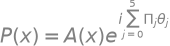

In [2]:
x = sp.Symbol("x")
A, P_ = sp.Function("A"), sp.Function("P")
j, k, m, c, N, th = dv.generic()
Pi = sp.IndexedBase("Pi")
display(sp.Eq(P_(x), A(x) * sp.exp(sp.I * sp.Sum(th[j] * Pi[j], (j, 0, 5)))))

At any point of the pupil exactly one Pi_j is 1 and the others are 0. So
the exponential of the sum equals the sum of the exponentials, weighted by
the indicators: the pupil field is a sum of the six petal masks, each
multiplied by its own phasor. sympy checks the identity at every petal:

lhs - rhs, with Pi_j = 1 and the others 0, for j = 0..5: [0, 0, 0, 0, 0, 0]


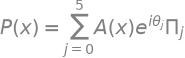

In [3]:
lhs, rhs, diffs = dv.pupil_phase_identity()
display(sp.Eq(lhs, rhs))
print("lhs - rhs, with Pi_j = 1 and the others 0, for j = 0..5:", diffs)
display(sp.Eq(P_(x), sp.Sum(A(x) * Pi[j] * sp.exp(sp.I * th[j]), (j, 0, 5))))

## 2. The PSF field at the lantern input

The field at the lantern's input face is the Fraunhofer diffraction pattern
of the pupil, in the simulation a zero-padded FFT. That is a linear operator
F. Applied to the sum, it gives the PSF field as the same phasors times six
fixed fields: E_j(u) is the focal-plane field of petal j alone.

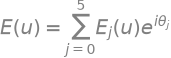

In [4]:
u = sp.Symbol("u"); E, Ej, F = sp.Function("E"), sp.IndexedBase("E"), sp.Function("F")
display(sp.Eq(E(u), F(P_(x))))
display(sp.Eq(E(u), sp.Sum(sp.exp(sp.I * th[j]) * sp.Function("E_j")(u), (j, 0, 5))))
display(sp.Eq(sp.Function("E_j")(u), F(A(x) * Pi[j])))

A numerical check with the simulation's own FFT (batch_pipeline). For a
random configuration, the PSF field computed directly is compared with the
phasor-weighted sum of the six single-petal fields:

In [5]:
p800 = bp.get_simulation_parameters(3, 0.8)
ifunc = bp.load_ifunc(p800["ifunc_file"]); bp.center_ifunc_mask(ifunc)
geom = petals.petal_geometry(ifunc.mask_inf_func, np.asarray(ifunc.influence_function))
pist = np.random.default_rng(0).uniform(-400, 400, 5)     # +-lambda/2 at 800 nm
print(f"pistons {pist.round(1)} nm: largest relative difference "
      f"{dv.fft_linearity_check(p800, ifunc, geom, pist):.1e}")

pistons [  82.2 -138.1 -275.4 -290.1  188. ] nm: largest relative difference 3.1e-16


## 3. Projection on the lantern's input modes

cbeam decomposes the input field on the lantern's guided modes v_m at the
input face. The projection is an overlap integral (with the finite-element
mass matrix), so it is linear. The modal coefficients are the phasors times
fixed coefficients g_mj, the projections of the single-petal fields:

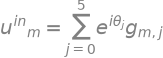

In [6]:
uin, g, v = sp.IndexedBase("u^{in}"), sp.IndexedBase("g"), sp.Function("v_m")
display(sp.Eq(uin[m], sp.Integral(sp.conjugate(v(u)) * E(u), u)))
display(sp.Eq(uin[m], sp.Sum(sp.exp(sp.I * th[j]) * g[m, j], (j, 0, 5))))
display(sp.Eq(g[m, j], sp.Integral(sp.conjugate(v(u)) * sp.Function("E_j")(u), u)))

## 4. Propagation through the lantern

The coupled-mode equations cbeam integrates are linear in the mode
amplitudes: du/dz = K(z) u, where K holds the coupling coefficients and the
propagation phases. Their solution is a fixed transfer matrix T, the same
for every input. The output is then expressed in the basis of the isolated
output channels (the cores) by a fixed matrix U, so each output channel's
amplitude is again a sum of the phasors times fixed coefficients h_jc:

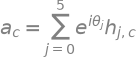

In [7]:
z_ = sp.Symbol("z"); uvec, K, T, U = sp.Function("u"), sp.Function("K"), sp.MatrixSymbol("T", 20, 20), sp.MatrixSymbol("U", 19, 20)
display(sp.Eq(sp.Derivative(uvec(z_), z_), K(z_) * uvec(z_)))
a, h = sp.IndexedBase("a"), sp.IndexedBase("h")
display(sp.Eq(a[c], sp.Sum(sp.exp(sp.I * th[j]) * h[j, c], (j, 0, 5))))
display(sp.Eq(h[j, c], sp.Symbol(r"\left(U\,T\,g_{j}\right)_c")))

## 5. Detection: a Hermitian quadratic form

A channel's power is the squared modulus of its amplitude. That is the only
nonlinear step. It turns the sum of phasors into a double sum over petal
pairs, weighted by the fixed products h_jc h_kc*:

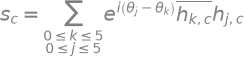

In [8]:
s = sp.IndexedBase("s")
display(sp.Eq(s[c], sp.Abs(a[c]) ** 2))
display(sp.Eq(s[c], sp.Sum(sp.Sum(sp.exp(sp.I * (th[j] - th[k])) * h[j, c] * sp.conjugate(h[k, c]),
                                  (k, 0, 5)), (j, 0, 5))))

A camera window gives the same form. simulate_core_images interpolates the
output intensity |sum_j z_j O_j(x)|^2 linearly from the mesh nodes to the
window pixels, and averages it. Each pixel value is a fixed weighted sum of
node intensities, so the window signal is the same double sum, with
h_jc h_kc* replaced by the window's weighted sum of O_j O_k*.

## 6. The real form

The (j, k) and (k, j) terms of the double sum are complex conjugates, so
each pair contributes twice its real part. Writing h_j = x_j + i y_j, sympy
expands the squared modulus for three petals, and checks that the
difference from the real form below is exactly zero (for two and three
petals; the pairing argument is the same for any number):

s_c = sum_j |h_jc|^2 + 2 sum_{j<k} [Re(h_jc h_kc*) cos(theta_j - theta_k) - Im(h_jc h_kc*) sin(theta_j - theta_k)]

In [9]:
power3, real3, diff3 = dv.quadratic_form(3)
display(sp.Eq(sp.Symbol("|a|^2"), power3))
display(sp.Eq(sp.Symbol("|a|^2"), real3))
print("difference, 3 petals:", diff3, "   2 petals:", dv.quadratic_form(2)[2])

difference, 3 petals: 0    2 petals: 0


So each channel's power is a constant plus a linear combination of cos and
sin of the 15 pairwise phase differences:

- a_c = sum_j |h_jc|^2
- A_c,jk = 2 Re(h_jc h_kc*)
- B_c,jk = -2 Im(h_jc h_kc*)

## 7. Only phase differences: the reference petal

The real form depends on the phases only through their differences. sympy
checks that adding the same phase phi to every petal (a global piston)
leaves it unchanged. So one petal can be fixed: the reference R of the
modal basis has p_R = 0, and its differences with the others are just
their own phases. With D_jk = 2 pi (p_j - p_k) / lambda:

In [10]:
print("real form after theta_j -> theta_j + phi, minus before:", dv.global_piston_invariance(3))
lam_ = sp.Symbol("lambda", positive=True); p_ = sp.IndexedBase("p")
display(sp.Eq(sp.Symbol("D_{jk}"), 2 * sp.pi * (p_[j] - p_[k]) / lam_))
display(sp.Eq(sp.Symbol("D_{jR}"), 2 * sp.pi * p_[j] / lam_))

real form after theta_j -> theta_j + phi, minus before: 0


## 8. Normalisation: the ratio

The camera signals of the single-wavelength dataset come from input fields
normalised to unit coupled power. batch_pipeline divides the input modal
vector by its norm, so every output power is divided by |u_in|^2. That is
again a quadratic form in the phasors, with G_jk = sum_m g_mj g_mk*.
Dividing numerator and denominator by its constant term Q_0 = sum_j G_jj
gives the closed form used in `symbolic.ipynb`:

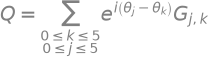

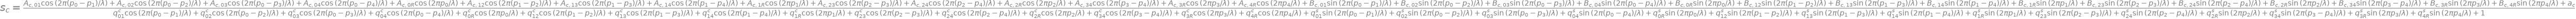

In [11]:
Q, G = sp.Symbol("Q"), sp.IndexedBase("G")
display(sp.Eq(Q, sp.Sum(sp.Sum(sp.exp(sp.I * (th[j] - th[k])) * G[j, k], (k, 0, 5)), (j, 0, 5))))
closed, p_free, lam_cf = dv.closed_form()
display(closed)

The denominator constants are q^c_jk = 2 Re(G_jk) / Q_0 and
q^s_jk = -2 Im(G_jk) / Q_0. They are the same for every core. For channel
powers that are fractions of the incident light, as in the spectral
dataset, there is no normalisation and the denominator is 1.

## 9. Counting the constants

There are 15 pairs. Each core has 1 + 2 x 15 numerator constants, and the
shared denominator has 2 x 15:

In [12]:
expr, value = dv.count_constants()
display(sp.Eq(sp.Symbol("n_{constants}"), expr))
print("for 19 cores and 6 petals:", value)

for 19 cores and 6 petals: 619


## 10. The constants from first principles

No fitting from here on. The six single-petal fields Pi_j(x), with unit
amplitude on one petal and zero elsewhere, go through the simulation's FFT,
the projection on the lantern modes and the cbeam propagation (about a
minute, mostly loading the lantern characterization). That gives h_jc and
g_mj, and from them the constants of sections 6 and 8. Three comparisons:

1. the channel powers they predict, against the spectral dataset at 800 nm
   (pistons in +-5 um, a full cbeam simulation per sample);
2. the numerator constants a, A, B, against those fitted by least squares
   in `symbolic.ipynb`;
3. the denominator constants q, against those fitted to the camera dataset.

In [13]:
h_fp, g_fp, prop12 = dv.petal_channel_amplitudes(p800, ifunc, geom)
chan = ml.LanternDataset.load("data/ml/spectral_41wl.npz"); w800 = int(np.argmin(np.abs(chan.wavelengths_nm - 800)))
S_pred = dv.channel_powers_from_amplitudes(h_fp, chan.coeff[:5000], 800.0)
S_true = chan.signals[:5000, w800]
print(f"1. channel powers, first principles vs full simulation: largest difference "
      f"{np.abs(S_pred - S_true).max() / S_true.max():.1e} of the largest power")


  loaded cached characterization '19port_0800_front'

  loaded cached characterization '19port_0800_back'
[Interpolation Setup]
  Padded grid size: 1600
  Grid parity: even
  Center offset: 800.0
  Pixel scale: 0.5532786885245902 μm/pixel
  Mesh X range: [-27.000, 27.000] μm
  Mesh Y range: [-26.852, 26.852] μm
  Valid interpolation points: 12495 / 12495
1. channel powers, first principles vs full simulation: largest difference 5.2e-04 of the largest power


In [14]:
a_fp, A_fp, B_fp = dv.constants_from_amplitudes(h_fp)
fit = fw.fit_forward(chan.coeff[:10000], chan.signals[:10000, w800], 800.0, normalised=False)
rel = lambda x, y: np.abs(x - y).max() / np.abs(y).max()
print(f"2. numerator, fitted vs first principles: a {rel(fit.a, a_fp):.1e}, A {rel(fit.W[:, :15], A_fp):.1e}, "
      f"B {rel(fit.W[:, 15:], B_fp):.1e}")
cam = ml.LanternDataset.load("data/ml/single_800nm_50k.npz")
q_fit = fw.fit_forward(cam.coeff[:10000], cam.signals[:10000], 800.0).q
print(f"3. denominator, fitted (camera) vs first principles: largest difference "
      f"{np.abs(q_fit - np.r_[dv.denominator_from_modes(g_fp)]).max():.1e} (largest |q| {np.abs(q_fit).max():.3f})")

2. numerator, fitted vs first principles: a 2.6e-04, A 3.3e-04, B 1.0e-03
3. denominator, fitted (camera) vs first principles: largest difference 6.6e-06 (largest |q| 0.036)


The derivation holds end to end. Six propagations through the lantern give
every constant, and the closed form then reproduces a full simulation of
any piston configuration, to the accuracy of the ODE solver. On a real
instrument the same constants can be measured instead, from a few known
configurations (`symbolic.ipynb`, section 7f).

## 11. The Jacobian and the Gauss-Newton step

The inversion needs ds_c/dp_j. The derivative of the phases is
dD_jk/dp_j = 2 pi / lambda, and dD_jk/dp_k = -2 pi / lambda. Writing the
closed form as N / Q, its derivative is (N' Q - N Q') / Q^2. For a small
case, two free petals plus the reference, sympy gives:

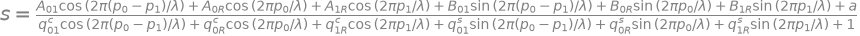

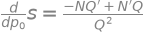

In [15]:
s_small, p_small, ds_small, (num_s, den_s) = dv.jacobian_small(2)
display(sp.Eq(sp.Symbol("s"), s_small))
display(sp.Eq(sp.Derivative(sp.Symbol("N"), p_small[0]), sp.simplify(sp.diff(num_s, p_small[0]))))
display(sp.Eq(sp.Derivative(sp.Symbol("s"), p_small[0]),
              (sp.Symbol("N'") * sp.Symbol("Q") - sp.Symbol("N") * sp.Symbol("Q'")) / sp.Symbol("Q") ** 2))

With the 19 x 5 Jacobian J and the residual r = s - s(p), each Gauss-Newton
iteration solves a 5 x 5 linear system:

In [16]:
Jm, r_, dp = sp.MatrixSymbol("J", 19, 5), sp.MatrixSymbol("r", 19, 1), sp.MatrixSymbol(r"\Delta p", 5, 1)
display(sp.Eq(dp, (Jm.T * Jm).I * Jm.T * r_))

## 12. Summary

| step | operation | linear in the field? | result |
|---|---|---|---|
| 1 | pupil phase on disjoint petals | - | P = sum_j z_j A Pi_j |
| 2 | zero-padded FFT to the lantern input | yes | E = sum_j z_j E_j |
| 3 | projection on the input modes | yes | u_in = sum_j z_j g_j |
| 4 | cbeam propagation, output channels | yes | a_c = sum_j z_j h_jc |
| 5 | detection | no: squared modulus | s_c = sum_jk z_j z_k* h_jc h_kc* |
| 6 | pairing of conjugate terms | - | a_c + sum_{j<k} A cos D + B sin D |
| 7 | global piston | - | only the differences D_jk; p_R = 0 |
| 8 | normalisation by the coupled power | same form | ratio with 1 + q . z |
| 9 | constants | - | 19 x 31 + 30 = 619 |

The form is exact for piston-only aberrations at one wavelength, because
then the input field is a fixed combination of six petal fields. With other
aberrations the petal fields themselves change (`symbolic.ipynb`, section
7e). With several wavelengths, each wavelength has its own constants.